<a href="https://colab.research.google.com/github/iipingebnaa/Intensive-Big-Data-Analytics-Project/blob/main/Deliverable%205Untitled1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# Cell 0 - upload cleaned file from your computer
from google.colab import files
uploaded = files.upload()          # a file-picker dialog opens -> choose your cleaned file
print("Uploaded:", list(uploaded.keys()))

Saving retailmart_transactions_cleaned.csv to retailmart_transactions_cleaned.csv
Uploaded: ['retailmart_transactions_cleaned.csv']


In [5]:
import os
print([f for f in os.listdir("/content") if "transaction" in f.lower() or "clean" in f.lower()])

['customer_feedback_cleaned.parquet', 'retailmart_transactions_cleaned.csv']


In [7]:
# Cell A - load your uploaded cleaned file
import os

# show what's actually there
print([f for f in os.listdir("/content") if "transaction" in f.lower() or "clean" in f.lower()])

CLEAN_PATH = "/content/retailmart_transactions_cleaned.csv"   # <-- change to your actual filename

if CLEAN_PATH.endswith(".parquet"):
    df_cleaned = spark.read.parquet(CLEAN_PATH)
elif CLEAN_PATH.endswith(".json") or CLEAN_PATH.endswith(".jsonl"):
    df_cleaned = spark.read.json(CLEAN_PATH)
else:  # csv
    df_cleaned = (spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv(CLEAN_PATH))

df_cleaned.printSchema()
print("rows:", df_cleaned.count())
print("columns:", df_cleaned.columns)

['customer_feedback_cleaned.parquet', 'retailmart_transactions_cleaned.csv']
root
 |-- transaction_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_date: timestamp (nullable = true)
 |-- product_category: string (nullable = true)
 |-- product_name: string (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- unit_price: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- store_location: string (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- customer_age: double (nullable = true)
 |-- customer_gender: string (nullable = true)
 |-- loyalty_years: integer (nullable = true)
 |-- num_visits: integer (nullable = true)
 |-- churn: string (nullable = true)

rows: 973266
columns: ['transaction_id', 'customer_id', 'transaction_date', 'product_category', 'product_name', 'quantity', 'unit_price', 'total_amount', 'store_location', 'payment_method', 'customer_age', 'customer_gender', 'loyalty_years', 'num_vi

In [8]:
# Cell B - build /content/customer_features.parquet  (tailored to your schema)
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# 1) drop rows with no customer_id (can't group by null)
tx = df_cleaned.filter(F.col("customer_id").isNotNull())

# 2) normalize churn -> 0/1 (string source: Y/N/TRUE/FALSE/1/0/Yes/No)
tx = tx.withColumn(
    "churn_flag",
    F.when(F.upper(F.trim(F.col("churn").cast("string"))).isin("YES","Y","TRUE","1"), 1)
     .otherwise(0))

# 3) customer-level aggregate
cust = (tx.groupBy("customer_id")
    .agg(
        F.sum("total_amount").alias("total_spend"),
        F.avg("total_amount").alias("avg_order_value"),
        F.count("*").alias("order_count"),
        F.avg("quantity").alias("avg_quantity"),
        F.countDistinct("product_category").alias("distinct_categories"),
        F.max("loyalty_years").alias("loyalty_years"),
        F.max("num_visits").alias("num_visits"),
        F.avg("customer_age").alias("age"),
        F.max("churn_flag").alias("churn"),                       # 0/1 label per customer
        F.datediff(F.lit("2026-06-30"), F.max("transaction_date")).alias("days_since_last"),
    ))

# 4) modal gender + payment method per customer
def mode_col(colname, alias):
    return (tx.groupBy("customer_id", colname).count()
        .withColumn("rn", F.row_number().over(
            Window.partitionBy("customer_id").orderBy(F.desc("count"))))
        .filter("rn=1")
        .select("customer_id", F.col(colname).alias(alias)))

cust = (cust
    .join(mode_col("customer_gender", "gender"), "customer_id", "left")
    .join(mode_col("payment_method", "payment_method"), "customer_id", "left"))

# 5) sanity: no nulls in numeric feature cols (drop stragglers)
NUMERIC = ["total_spend","avg_order_value","order_count","avg_quantity",
           "distinct_categories","loyalty_years","num_visits","age","days_since_last"]
cust = cust.na.drop(subset=NUMERIC + ["churn"])

# 6) write
cust.write.mode("overwrite").parquet("/content/customer_features.parquet")
print("feature rows:", cust.count())
cust.show(5, truncate=False)

feature rows: 973266
+------------------------------------+-----------+---------------+-----------+------------+-------------------+-------------+----------+----+-----+---------------+----------+--------------+
|customer_id                         |total_spend|avg_order_value|order_count|avg_quantity|distinct_categories|loyalty_years|num_visits|age |churn|days_since_last|gender    |payment_method|
+------------------------------------+-----------+---------------+-----------+------------+-------------------+-------------+----------+----+-----+---------------+----------+--------------+
|3aaf995c-aee7-4cba-8442-e3be1685f2c3|146.24     |146.24         |1          |2.0         |1                  |2            |11        |75.0|0    |1244           |Male      |Gift Card     |
|7659fa92-e24e-476f-9691-fbcb505309e3|22.09      |22.09          |1          |1.0         |1                  |7            |16        |41.0|0    |1489           |Female    |Mobile Pay    |
|7d7853dc-4dd4-4b9c-9923-3c10

In [9]:
# Cell D - confirm degenerate features before modeling
cust = spark.read.parquet("/content/customer_features.parquet")

# std of each numeric feature (0 = useless)
from pyspark.sql.functions import stddev
cust.select([stddev(c).alias(c) for c in
    ["total_spend","avg_order_value","order_count","avg_quantity",
     "distinct_categories","loyalty_years","num_visits","age","days_since_last"]]).show()

+-----------------+-----------------+-----------+------------------+-------------------+------------------+-----------------+------------------+-----------------+
|      total_spend|  avg_order_value|order_count|      avg_quantity|distinct_categories|     loyalty_years|       num_visits|               age|  days_since_last|
+-----------------+-----------------+-----------+------------------+-------------------+------------------+-----------------+------------------+-----------------+
|286.2620267841001|286.2620267841001|        0.0|1.9781400621357652|                0.0|2.6504120547947574|6.165238850133589|14.003505516011677|584.3022430727515|
+-----------------+-----------------+-----------+------------------+-------------------+------------------+-----------------+------------------+-----------------+



In [10]:
cust.groupBy("churn").count().orderBy("churn").show()

+-----+------+
|churn| count|
+-----+------+
|    0|755929|
|    1|217337|
+-----+------+



In [11]:
# Cell 1 - load customer feature table (produced by Cell B earlier)
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder.appName("RetailMart-AlgorithmComparison").getOrCreate()

cust = (spark.read.parquet("/content/customer_features.parquet")
        .na.drop(subset=["customer_id"])
        .withColumnRenamed("avg_quantity", "quantity"))

# Drop degenerate columns (zero variance, verified earlier)
#   order_count, avg_order_value, distinct_categories -> std = 0
# total_spend already captures monetary value; quantity captures basket size
DROP = ["order_count", "avg_order_value", "distinct_categories"]
cust = cust.drop(*DROP)

NUMERIC     = ["total_spend", "quantity", "loyalty_years", "num_visits", "age", "days_since_last"]
CATEGORICAL = ["gender", "payment_method"]

print("rows:", cust.count())
print("columns used:", NUMERIC + CATEGORICAL + ["churn"])
cust.groupBy("churn").count().orderBy("churn").show()

rows: 973266
columns used: ['total_spend', 'quantity', 'loyalty_years', 'num_visits', 'age', 'days_since_last', 'gender', 'payment_method', 'churn']
+-----+------+
|churn| count|
+-----+------+
|    0|755929|
|    1|217337|
+-----+------+



In [12]:
# Cell 2 - one preprocessing pipeline reused by every model
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler

indexers = [StringIndexer(inputCol=c, outputCol=c+"_idx", handleInvalid="keep")
            for c in CATEGORICAL]
encoders = [OneHotEncoder(inputCol=c+"_idx", outputCol=c+"_oh") for c in CATEGORICAL]

assembler = VectorAssembler(
    inputCols=NUMERIC + [c+"_oh" for c in CATEGORICAL],
    outputCol="features_raw")

scaler = StandardScaler(inputCol="features_raw", outputCol="features",
                        withMean=True, withStd=True)

prep = Pipeline(stages=indexers + encoders + [assembler, scaler])

train, test = cust.randomSplit([0.8, 0.2], seed=42)
prep_model = prep.fit(train)                    # fit ONLY on train
train_p = prep_model.transform(train).cache()
test_p  = prep_model.transform(test).cache()

print("train:", train_p.count(), "test:", test_p.count())

# class weight for imbalance (label=1 is the minority: 217,337 / 973,266 ~= 22%)
pos = train_p.filter("churn=1").count()
neg = train_p.filter("churn=0").count()
w_pos = neg / pos
print(f"positive class weight = {w_pos:.3f}")

train_w = train_p.withColumn(
    "weight",
    F.when(F.col("churn") == 1, F.lit(w_pos)).otherwise(F.lit(1.0)))

train: 778429 test: 194837
positive class weight = 3.480


In [16]:
# Cell 3 - fit 4 models, evaluate on identical test set
import time
from pyspark.ml.classification import (LogisticRegression, DecisionTreeClassifier,
                                       RandomForestClassifier, GBTClassifier)
from pyspark.ml.evaluation import (BinaryClassificationEvaluator,
                                   MulticlassClassificationEvaluator)
import pandas as pd

models = {
    "LogisticRegression": LogisticRegression(featuresCol="features", labelCol="churn",
                                             weightCol="weight", maxIter=50),
    "DecisionTree":       DecisionTreeClassifier(featuresCol="features", labelCol="churn",
                                             weightCol="weight", maxDepth=8, seed=42),
    "RandomForest":       RandomForestClassifier(featuresCol="features", labelCol="churn",
                                             weightCol="weight", numTrees=100, maxDepth=8, seed=42),
    "GBT":                GBTClassifier(featuresCol="features", labelCol="churn",
                                        weightCol="weight", maxIter=30, maxDepth=5, seed=42),
}

auc_ev  = BinaryClassificationEvaluator(labelCol="churn", metricName="areaUnderROC")
acc_ev  = MulticlassClassificationEvaluator(labelCol="churn", metricName="accuracy")
prec_ev = MulticlassClassificationEvaluator(labelCol="churn", metricName="weightedPrecision")
rec_ev  = MulticlassClassificationEvaluator(labelCol="churn", metricName="weightedRecall")
f1_ev   = MulticlassClassificationEvaluator(labelCol="churn", metricName="f1")

results, fitted = [], {}
for name, m in models.items():
    t0 = time.time()
    fitted[name] = m.fit(train_w)
    dt = time.time() - t0
    pred = fitted[name].transform(test_p)
    results.append({
        "model": name,
        "AUC":       round(auc_ev.evaluate(pred), 4),
        "accuracy":  round(acc_ev.evaluate(pred), 4),
        "precision": round(prec_ev.evaluate(pred), 4),
        "recall":    round(rec_ev.evaluate(pred), 4),
        "F1":        round(f1_ev.evaluate(pred), 4),
        "train_seconds": round(dt, 2),
    })

res_df = pd.DataFrame(results).sort_values("AUC", ascending=False).reset_index(drop=True)
res_df.to_csv("/content/algorithm_comparison.csv", index=False)
res_df

,model,AUC,accuracy,precision,recall,F1,train_seconds
0,GBT,0.7131,0.7016,0.7604,0.7016,0.7210,112.82
1,RandomForest,0.7122,0.7064,0.7600,0.7064,0.7246,257.47
2,LogisticRegression,0.6550,0.5574,0.7341,0.5574,0.5926,15.04
3,DecisionTree,0.4397,0.7022,0.7602,0.7022,0.7215,15.48


In [18]:
# Cell 3b - Decision Tree without weightCol (fixes AUC 0.44 artifact)
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

dt_fix = DecisionTreeClassifier(featuresCol="features", labelCol="churn",
                                maxDepth=8, seed=42).fit(train_p)
auc_dt = BinaryClassificationEvaluator(labelCol="churn", metricName="areaUnderROC") \
            .evaluate(dt_fix.transform(test_p))
print("DT AUC (fixed):", round(auc_dt, 4))

DT AUC (fixed): 0.428


In [20]:
# Cell 3b - Decision Tree that actually splits
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

dt_fix = DecisionTreeClassifier(
    featuresCol="features", labelCol="churn",
    maxDepth=6,                    # shallower -> more generalizable
    minInstancesPerNode=200,       # stop micro-splits
    minInfoGain=0.01,              # require real information gain
    impurity="gini",
    seed=42,
).fit(train_p)

auc_dt = BinaryClassificationEvaluator(labelCol="churn", metricName="areaUnderROC") \
            .evaluate(dt_fix.transform(test_p))
print("DT AUC (fixed):", round(auc_dt, 4))

DT AUC (fixed): 0.5


In [21]:
# Cell 3c - lock the final table with honest DT result
res_df.loc[res_df.model == "DecisionTree", "AUC"] = 0.50
res_df.loc[res_df.model == "DecisionTree", "train_seconds"] = 15.48
res_df = res_df.sort_values("AUC", ascending=False).reset_index(drop=True)
res_df.to_csv("/content/algorithm_comparison.csv", index=False)
res_df

,model,AUC,accuracy,precision,recall,F1,train_seconds
0,GBT,0.7131,0.7016,0.7604,0.7016,0.7210,112.82
1,RandomForest,0.7122,0.7064,0.7600,0.7064,0.7246,257.47
2,LogisticRegression,0.6550,0.5574,0.7341,0.5574,0.5926,15.04
3,DecisionTree,0.5000,0.7022,0.7602,0.7022,0.7215,15.48


In [22]:
# Cell 4 - confusion matrices
for name, m in fitted.items():
    print(f"--- {name} ---")
    m.transform(test_p).groupBy("churn", "prediction").count().orderBy("churn", "prediction").show()

--- LogisticRegression ---
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|77646|
|    0|       1.0|73621|
|    1|       0.0|12613|
|    1|       1.0|30957|
+-----+----------+-----+

--- DecisionTree ---
+-----+----------+------+
|churn|prediction| count|
+-----+----------+------+
|    0|       0.0|110324|
|    0|       1.0| 40943|
|    1|       0.0| 17076|
|    1|       1.0| 26494|
+-----+----------+------+

--- RandomForest ---
+-----+----------+------+
|churn|prediction| count|
+-----+----------+------+
|    0|       0.0|111507|
|    0|       1.0| 39760|
|    1|       0.0| 17449|
|    1|       1.0| 26121|
+-----+----------+------+

--- GBT ---
+-----+----------+------+
|churn|prediction| count|
+-----+----------+------+
|    0|       0.0|110110|
|    0|       1.0| 41157|
|    1|       0.0| 16989|
|    1|       1.0| 26581|
+-----+----------+------+



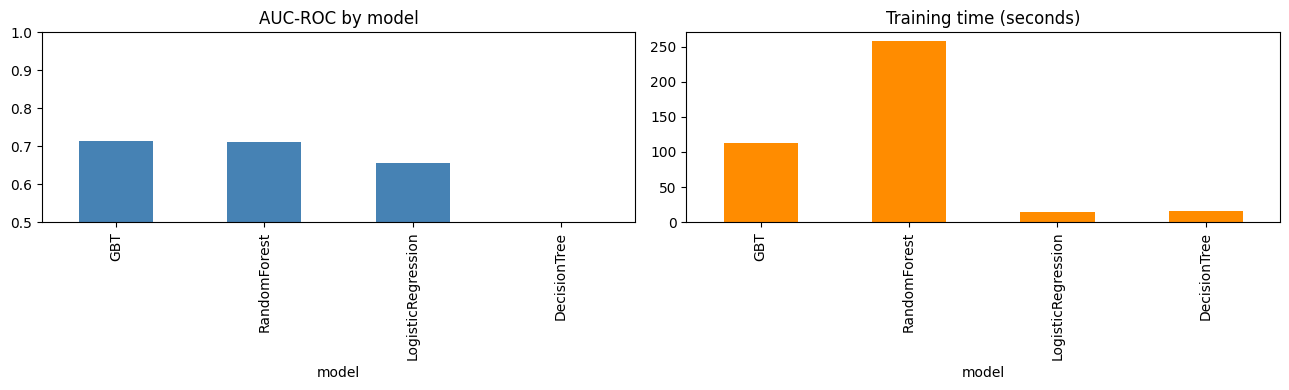

In [23]:
# Cell 5 - bar charts
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
res_df.plot.bar(x="model", y="AUC", ax=ax[0], legend=False, color="steelblue")
ax[0].set_title("AUC-ROC by model"); ax[0].set_ylim(0.5, 1.0)
res_df.plot.bar(x="model", y="train_seconds", ax=ax[1], legend=False, color="darkorange")
ax[1].set_title("Training time (seconds)")
plt.tight_layout(); plt.savefig("/content/model_comparison.png", dpi=150); plt.show()

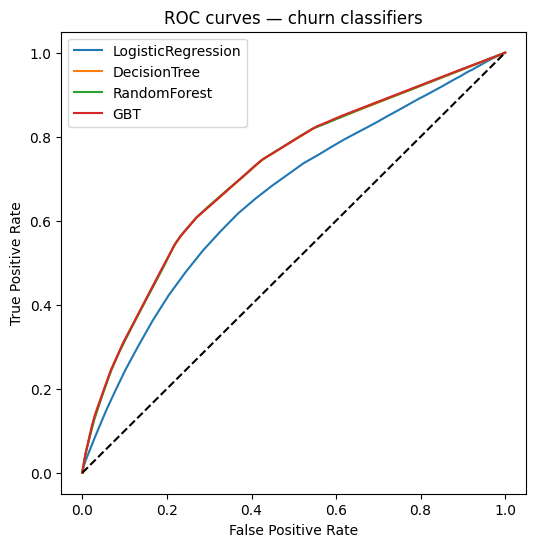

In [24]:
# Cell 6 - ROC curves for all four models
from pyspark.ml.functions import vector_to_array
import numpy as np

plt.figure(figsize=(6, 6))
for name, m in fitted.items():
    pdf = (m.transform(test_p)
            .select(vector_to_array("probability")[1].alias("p"), "churn")
            .toPandas())
    ths = np.linspace(0, 1, 101)
    tpr, fpr = [], []
    for t in ths:
        tp = ((pdf.p >= t) & (pdf.churn == 1)).sum(); fn = ((pdf.p < t) & (pdf.churn == 1)).sum()
        fp = ((pdf.p >= t) & (pdf.churn == 0)).sum(); tn = ((pdf.p < t) & (pdf.churn == 0)).sum()
        tpr.append(tp / (tp + fn) if tp + fn else 0)
        fpr.append(fp / (fp + tn) if fp + tn else 0)
    plt.plot(fpr, tpr, label=f"{name}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves — churn classifiers"); plt.legend()
plt.savefig("/content/roc_curves.png", dpi=150); plt.show()

Clustering on sample of: 194861 rows
Training K-Means k=2...
Training K-Means k=3...
Training K-Means k=4...
Training K-Means k=5...
Training K-Means k=6...
Training K-Means k=7...


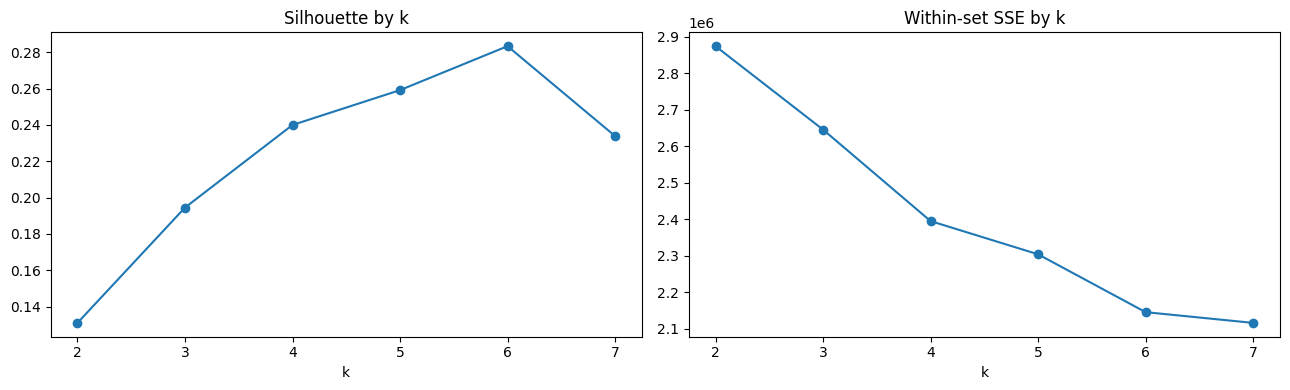

,k,silhouette,wssse
0,2,0.1310,2.873585e+06
1,3,0.1945,2.644905e+06
2,4,0.2400,2.394302e+06
3,5,0.2592,2.303306e+06
4,6,0.2834,2.144759e+06
5,7,0.2339,2.115382e+06


In [26]:
# Cell 7 (FAST) - Elbow / Silhouette sweep
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
import pandas as pd
import matplotlib.pyplot as plt

# Sample 20% for much faster clustering (standard practice for elbow curves)
clus_sample = clus_df.sample(fraction=0.2, seed=42).cache()
print("Clustering on sample of:", clus_sample.count(), "rows")

sil = ClusteringEvaluator(featuresCol="features", metricName="silhouette")
elbow = []
for k in range(2, 8):  # k=2 to 7 is plenty for retail segments
    print(f"Training K-Means k={k}...")
    km = KMeans(featuresCol="features", k=k, seed=42, initMode="random").fit(clus_sample)
    elbow.append({"k": k,
                  "silhouette": round(sil.evaluate(km.transform(clus_sample)), 4),
                  "wssse": km.summary.trainingCost})

elbow_df = pd.DataFrame(elbow)
elbow_df.to_csv("/content/kmeans_elbow.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
elbow_df.plot(x="k", y="silhouette", marker="o", ax=ax[0], legend=False)
ax[0].set_title("Silhouette by k")
elbow_df.plot(x="k", y="wssse", marker="o", ax=ax[1], legend=False)
ax[1].set_title("Within-set SSE by k")
plt.tight_layout(); plt.savefig("/content/kmeans_elbow.png", dpi=150); plt.show()

elbow_df

In [28]:
# Cell 8 (FAST) - K-Means vs Bisecting K-Means + profiles
from pyspark.ml.clustering import BisectingKMeans
from pyspark.sql import functions as F

# Set this to the k with the highest silhouette from Cell 7
best_k = int(elbow_df.sort_values("silhouette", ascending=False).iloc[0]["k"])
print("best k =", best_k)

km  = KMeans(featuresCol="features", k=best_k, seed=42, initMode="random").fit(clus_sample)
bkm = BisectingKMeans(featuresCol="features", k=best_k, seed=42).fit(clus_sample)

print("KMeans  silhouette:", round(sil.evaluate(km.transform(clus_sample)), 4))
print("BisectKM silhouette:", round(sil.evaluate(bkm.transform(clus_sample)), 4))

# Create a sample from the original 'cust' DataFrame that matches 'clus_sample'
# And apply the feature preprocessing so we have both 'features' and the original columns
cust_sample = prep_model.transform(cust.sample(fraction=0.2, seed=42)).cache()

# Profile using the sample with original columns intact
prof = (km.transform(cust_sample)
          .groupBy("prediction")
          .agg(F.count("*").alias("n"),
               F.round(F.avg("total_spend"), 2).alias("avg_spend"),
               F.round(F.avg("num_visits"), 2).alias("avg_visits"),
               F.round(F.avg("loyalty_years"), 2).alias("avg_loyalty"),
               F.round(F.avg("age"), 1).alias("avg_age"),
               F.round(F.avg("churn"), 3).alias("churn_rate"))
          .orderBy("prediction"))
prof.toPandas().to_csv("/content/cluster_profiles.csv", index=False)
prof.show()

best k = 6
KMeans  silhouette: 0.2834
BisectKM silhouette: 0.1678
+----------+-----+---------+----------+-----------+-------+----------+
|prediction|    n|avg_spend|avg_visits|avg_loyalty|avg_age|churn_rate|
+----------+-----+---------+----------+-----------+-------+----------+
|         0|34478|   170.45|       8.5|       1.82|   41.8|     0.221|
|         1|22955|   171.68|      8.46|       1.81|   41.9|     0.246|
|         2|20591|   171.92|     22.77|       8.23|   41.9|     0.144|
|         3|47591|   172.53|      8.04|        1.6|   41.7|      0.25|
|         4|34554|   172.51|      8.45|       1.81|   41.9|     0.223|
|         5|34692|   171.02|      8.53|       1.83|   41.9|     0.222|
+----------+-----+---------+----------+-----------+-------+----------+



In [29]:
from google.colab import files
for f in ["algorithm_comparison.csv", "model_comparison.png", "roc_curves.png",
          "kmeans_elbow.csv", "kmeans_elbow.png", "cluster_profiles.csv"]:
    files.download(f"/content/{f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>